In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv('/Users/veliaalaminos/Desktop/DAFT_July2025/labs/Week 5/lab-eda-univariate/amz_uk_price_prediction_dataset.csv')

In [4]:
df.shape

(2443651, 9)

In [5]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [6]:
### Part 1: Analyzing Best-Seller Trends Across Product Categories
## 1. Crosstab Analysis between the product category and the isBestSeller status

crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [7]:
# Calculate the proportion of best-sellers per category
crosstab_result['bestSeller_rate'] = (
    crosstab_result[True] / (crosstab_result[True] + crosstab_result[False])
)

crosstab_result['bestSeller_rate']

category
3D Printers                       0.004032
3D Printing & Scanning            0.000492
Abrasive & Finishing Products     0.020000
Action Cameras                    0.000589
Adapters                          0.011811
                                    ...   
Wind Instruments                  0.028000
Window Treatments                 0.020921
Women                             0.011985
Women's Sports & Outdoor Shoes    0.010209
eBook Readers & Accessories       0.000000
Name: bestSeller_rate, Length: 296, dtype: float64

In [8]:
# Sort categories by best-seller rate
sorted_result = crosstab_result.sort_values(by='bestSeller_rate', ascending=False)

sorted_result


isBestSeller,False,True,bestSeller_rate
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [9]:
# Display top 10 categories with the highest proportion of best-sellers
sorted_result.head(10)

isBestSeller,False,True,bestSeller_rate
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


In [10]:
from scipy.stats import chi2_contingency

# Chi-square test for product category and the isBestSeller status
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36684.23786636857), np.float64(0.0))

In [11]:
p_value = chi2_contingency(crosstab_result)[1]
p_value

np.float64(0.0)

The null hypothesis of the Chi-square test is that the two categorical variables are independent. Given the extremely low \( p \)-value, we reject the null hypothesis. This implies that there's a significant association between `category` and `isBestSeller` in the dataset.

In [12]:
from scipy.stats import chi2_contingency
import numpy as np

# 1. Keep only counts (exclude bestSeller_rate if it exists)
observed = crosstab_result.iloc[:, :2]

# 2. Run Chi-square test on counts
chi2, p, dof, expected = chi2_contingency(observed)

# 3. Total number of observations
n = observed.to_numpy().sum()

# 4. Minimum dimension (rows vs columns)
min_dim = min(observed.shape) - 1

# 5. Apply formula for Cramér's V
cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Chi-square:", chi2)
print("p-value:", p)
print("Cramér's V:", cramers_v)

Chi-square: 36540.20270061387
p-value: 0.0
Cramér's V: 0.1222829439760564


The Cramér's V value of 0.122 suggests a weak association between the two variables. Though statistically significant, the strength of this relationship is not very strong in practical terms.

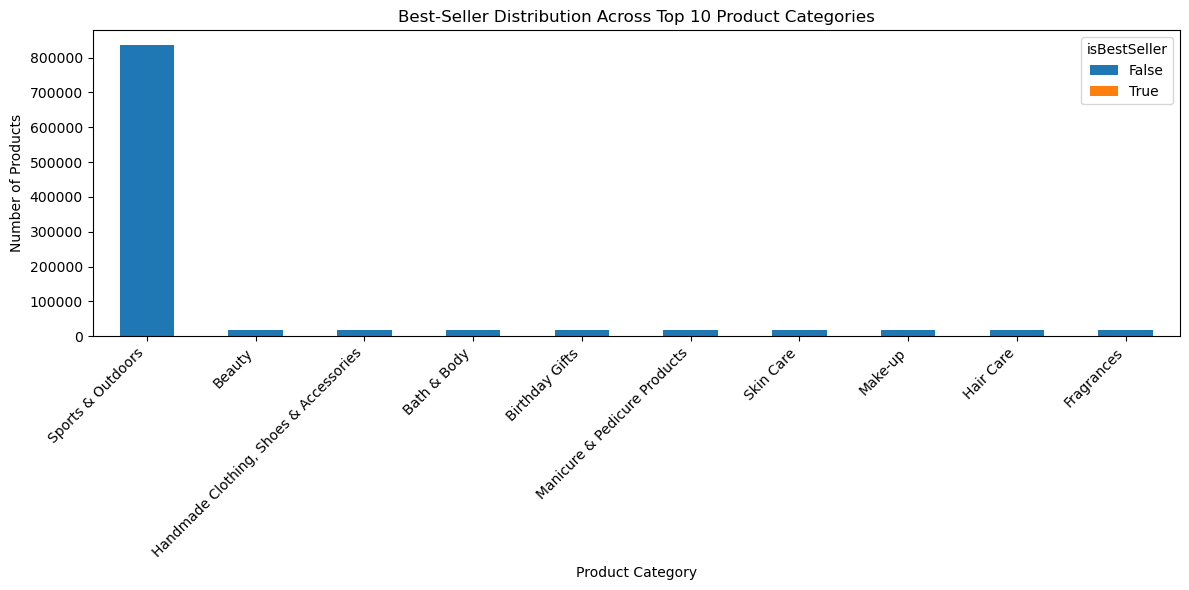

In [13]:
### 3. Visualization using a stacked bar chart 
top_categories = observed.sum(axis=1).sort_values(ascending=False).head(10)
observed_top = observed.loc[top_categories.index]

# Plot stacked bar chart
observed_top.plot(kind='bar', stacked=True, figsize=(12,6))

plt.title("Best-Seller Distribution Across Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(title="isBestSeller", labels=["False", "True"])
plt.tight_layout()
plt.show()

In [15]:
### Part 2: Exploring Product Prices and Ratings Across Categories and Brands
# 0. Remove outliers in product prices

# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
Q1, Q3


(np.float64(9.99), np.float64(45.99))

In [16]:
#Interquartile Range (IQR)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 *IQR
upper_bound = Q3+ 1.5 * IQR

print("Price lower bound: ", lower_bound)
print("Price upper bound: ", upper_bound)



Price lower bound:  -44.01
Price upper bound:  99.99000000000001


In [18]:
#Filter the dataframe to keep only values within bounds
df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [19]:
print("Original dataset size: ", df.shape[0])
print("Dataset size after removing outliers: ", df_no_outliers.shape[0])

Original dataset size:  2443651
Dataset size after removing outliers:  2115963


In [20]:
#1. Violin Plots
#Select top 20 categories by number of products
top20_categories = (df_no_outliers["category"].value_counts().head(20).index)

top20_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

In [ ]:
#Filter the dataframe
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20_categories)]

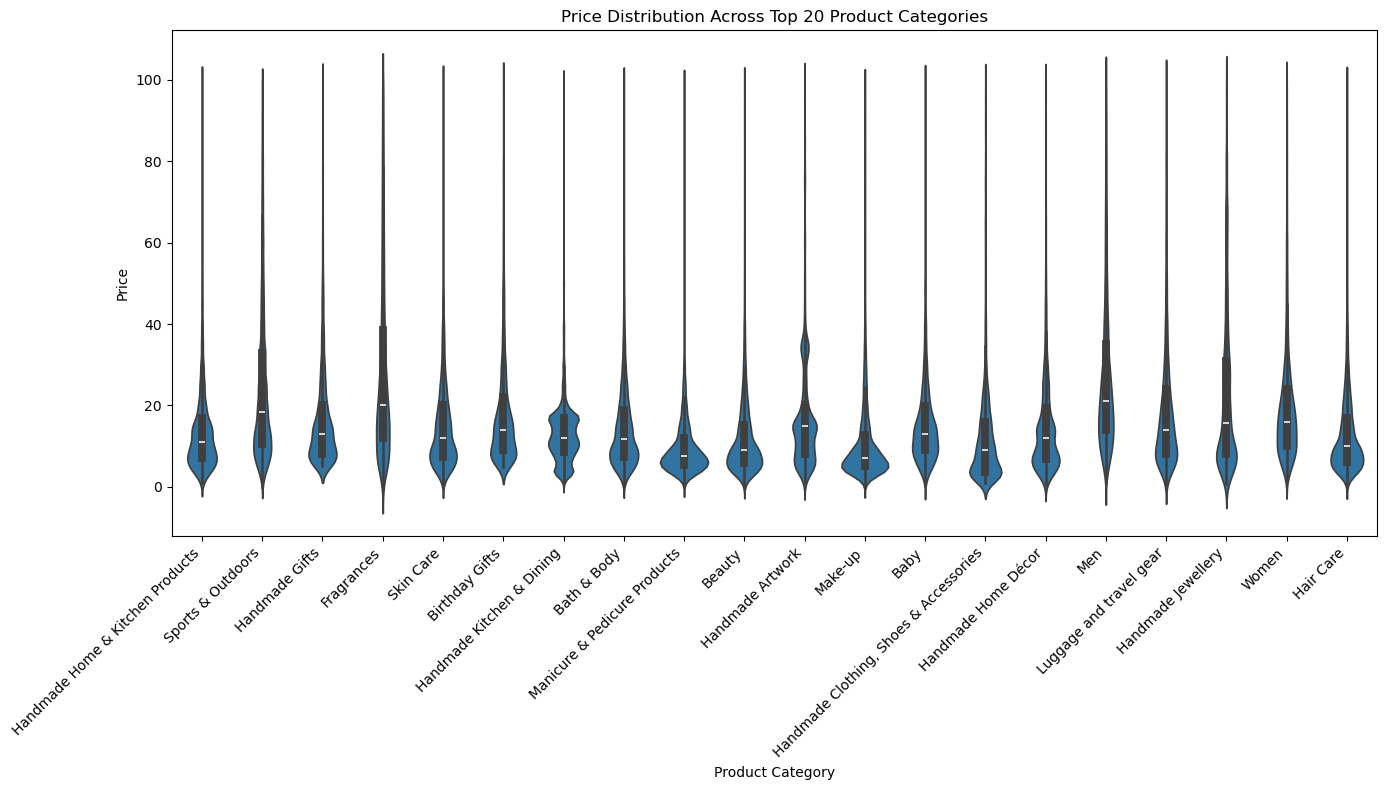

In [22]:
#Plot violin
plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top20, x="category", y="price", inner="box")
plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [23]:
#Group by category and get the median price
median_prices = df_no_outliers.groupby("category")["price"].median()
median_prices

category
3D Printers                       52.195
3D Printing & Scanning            28.580
Abrasive & Finishing Products     10.150
Action Cameras                    33.135
Adapters                           7.050
                                   ...  
Wind Instruments                  13.470
Window Treatments                 17.990
Women                             15.990
Women's Sports & Outdoor Shoes    45.990
eBook Readers & Accessories       21.990
Name: price, Length: 296, dtype: float64

In [24]:
#Sort to find the category with the highest median price
highest_median_category = median_prices.sort_values(ascending=False).head(1)

highest_median_category

category
Desktop PCs    74.0
Name: price, dtype: float64

In [25]:
print("Category with highest median price: ")
print(highest_median_category)

Category with highest median price: 
category
Desktop PCs    74.0
Name: price, dtype: float64


In [27]:
#2. Bar Charts comparing average price of products for the top 10 product categories
#Compute average price for each category
avg_prices = df_no_outliers.groupby("category")["price"].mean()
avg_prices

category
3D Printers                       55.739722
3D Printing & Scanning            35.623904
Abrasive & Finishing Products     14.427611
Action Cameras                    38.936875
Adapters                           8.750197
                                    ...    
Wind Instruments                  18.935339
Window Treatments                 19.870633
Women                             20.408735
Women's Sports & Outdoor Shoes    49.425894
eBook Readers & Accessories       26.006952
Name: price, Length: 296, dtype: float64

In [28]:
#Select the top 10 categories by product count
top10_categories = (df_no_outliers["category"].value_counts().head(10).index)
top10_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [30]:
#Filter only those categories
avg_prices_top10 = avg_prices.loc[top10_categories]
avg_prices_top10

category
Sports & Outdoors                         25.172065
Beauty                                    12.523480
Bath & Body                               14.678683
Manicure & Pedicure Products              10.231825
Handmade Clothing, Shoes & Accessories    12.958639
Make-up                                   10.612918
Skin Care                                 15.654722
Hair Care                                 13.461408
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Name: price, dtype: float64

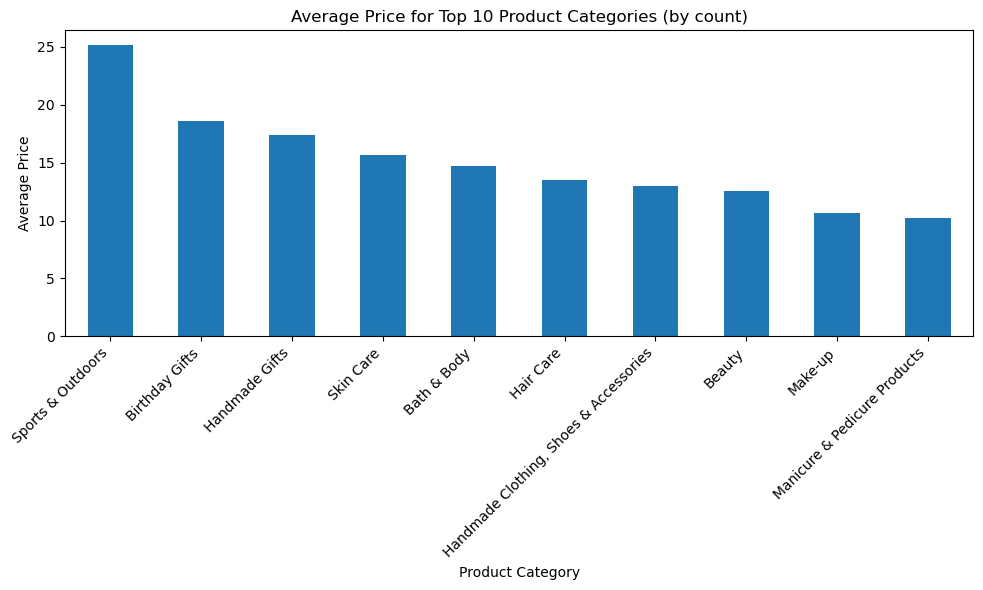

In [31]:
#Plot bar chart
plt.figure(figsize=(10,6))
avg_prices_top10.sort_values(ascending=False).plot(kind="bar")

plt.title("Average Price for Top 10 Product Categories (by count)")
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [32]:
#Category with the highest average price
highest_avg_price_category = avg_prices.sort_values(ascending=False).head(1)
highest_avg_price_category

category
Motherboards    68.772432
Name: price, dtype: float64

In [33]:
#3. Visualize the dist. of product "rating" based on their "category" using side-by-side box plots.
top10_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [34]:
#Filter the dataframe
df_top10 = df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
df_top10

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


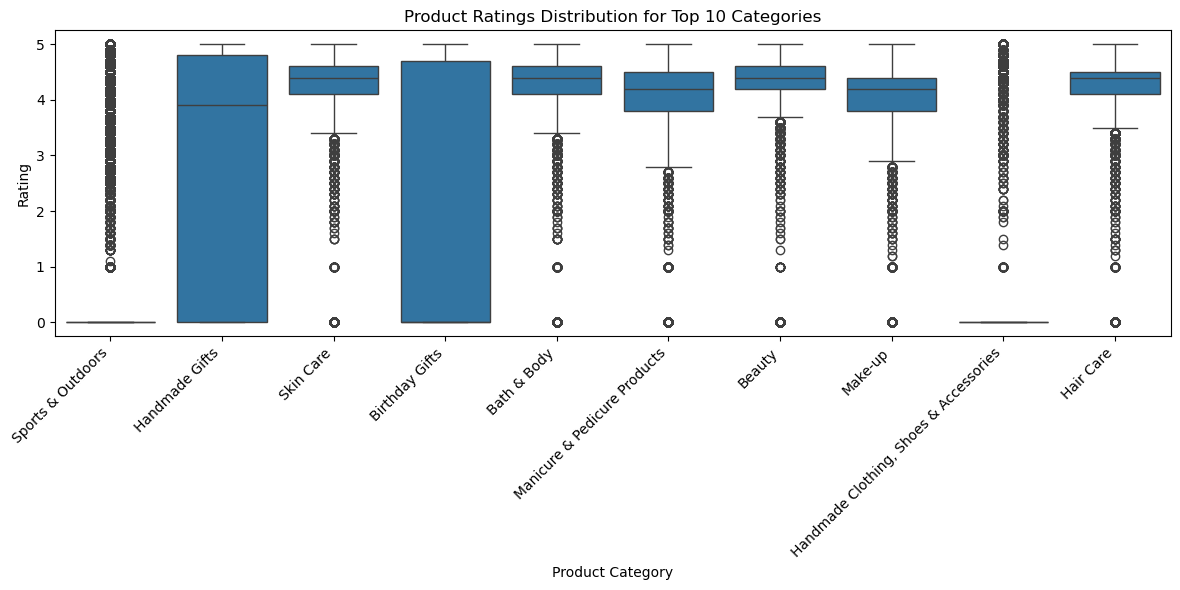

In [36]:
# Plot box plots
plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10, x="category", y="stars")
plt.xticks(rotation=45, ha="right")
plt.title("Product Ratings Distribution for Top 10 Categories")
plt.xlabel("Product Category")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

In [37]:
#Calculate the median rating for each category
median_ratings = df_no_outliers.groupby("category")["stars"].median()
median_ratings

category
3D Printers                       4.1
3D Printing & Scanning            0.0
Abrasive & Finishing Products     4.5
Action Cameras                    0.0
Adapters                          4.4
                                 ... 
Wind Instruments                  4.1
Window Treatments                 4.4
Women                             4.3
Women's Sports & Outdoor Shoes    4.3
eBook Readers & Accessories       0.0
Name: stars, Length: 296, dtype: float64

In [39]:
#Sort and find the category with the highest median rating
highest_median_rating_category = median_ratings.sort_values(ascending=False).head(1)
highest_median_rating_category

category
Computer Memory    4.7
Name: stars, dtype: float64

In [40]:
### Part 3: Investigating the Interplay between Product prices and ratings
#1. Correlation Coefficients
# Calculate Pearson correlation between price and stars
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])

print("Correlation between price and stars:", correlation)


Correlation between price and stars: -0.0776729987818131


There is a very weak negative correlation between price and ratings.
In practice, this suggests that price and customer rating are almost independent — higher-priced products do not necessarily get higher or lower ratings.

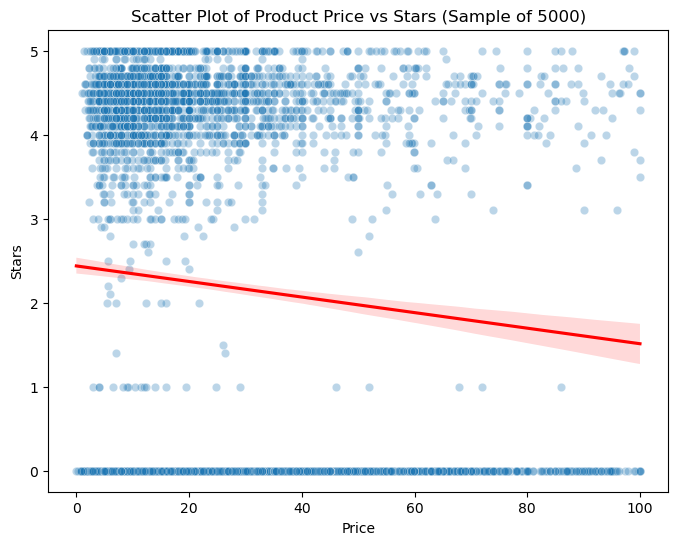

In [44]:
#2. Visualizations

# Random sample of 5000 products
df_sample = df_no_outliers.sample(5000, random_state=42)

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_sample, x='price', y='stars', alpha=0.3)
sns.regplot(data=df_sample, x='price', y='stars', scatter=False, color='red')
plt.title("Scatter Plot of Product Price vs Stars (Sample of 5000)")
plt.xlabel("Price")
plt.ylabel("Stars")
plt.show()

***Pattern to observe: ***

- The red line shows the trend.
- With your correlation (-0.078), the trend is almost flat → ratings are mostly independent of price.
- Most ratings are spread across all price ranges.

In [46]:
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


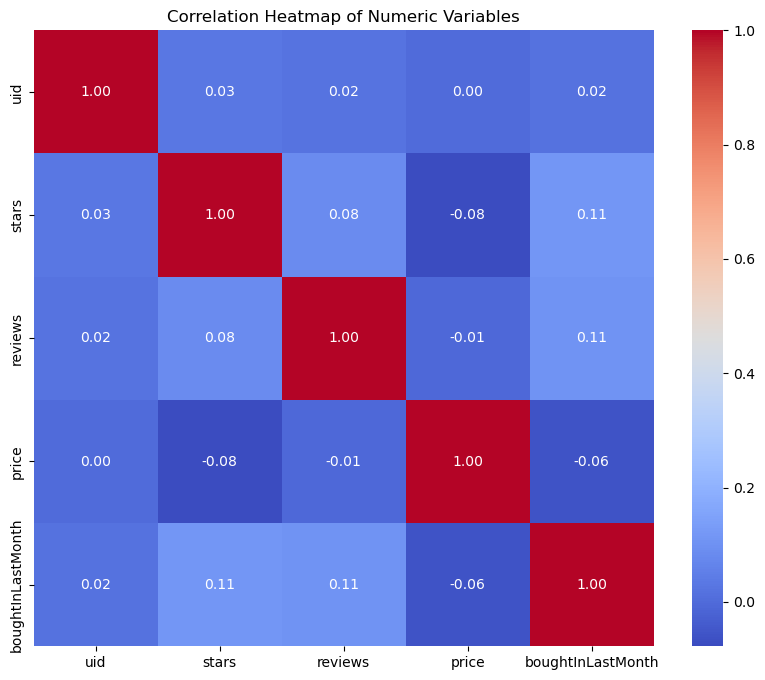

In [47]:
#Correlation Heatmap of Numerical Variables
# Select only numeric columns
numeric_df = df_no_outliers.select_dtypes(include=['float64', 'int64'])

# Plot correlation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

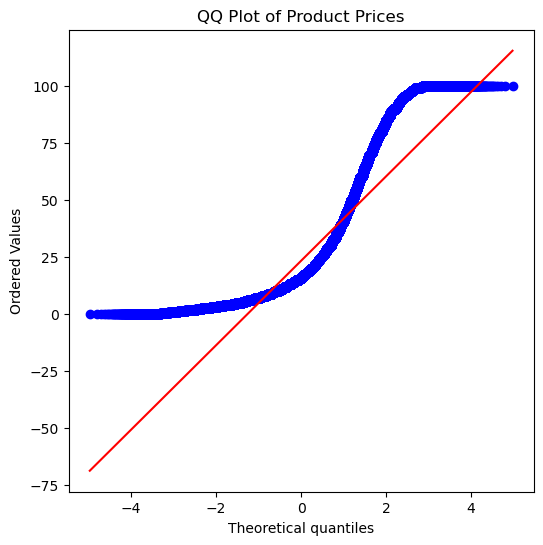

In [49]:
import scipy.stats as stats

#QQ Plot to check if prices are normally distributed
plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()

🔴 The red line represents how the prices would be distributed if they followed a perfect normal distribution.

🔵 The blue dots are your actual prices compared against that theoretical distribution.

***Conclusion***
- The product prices are not normally distributed.

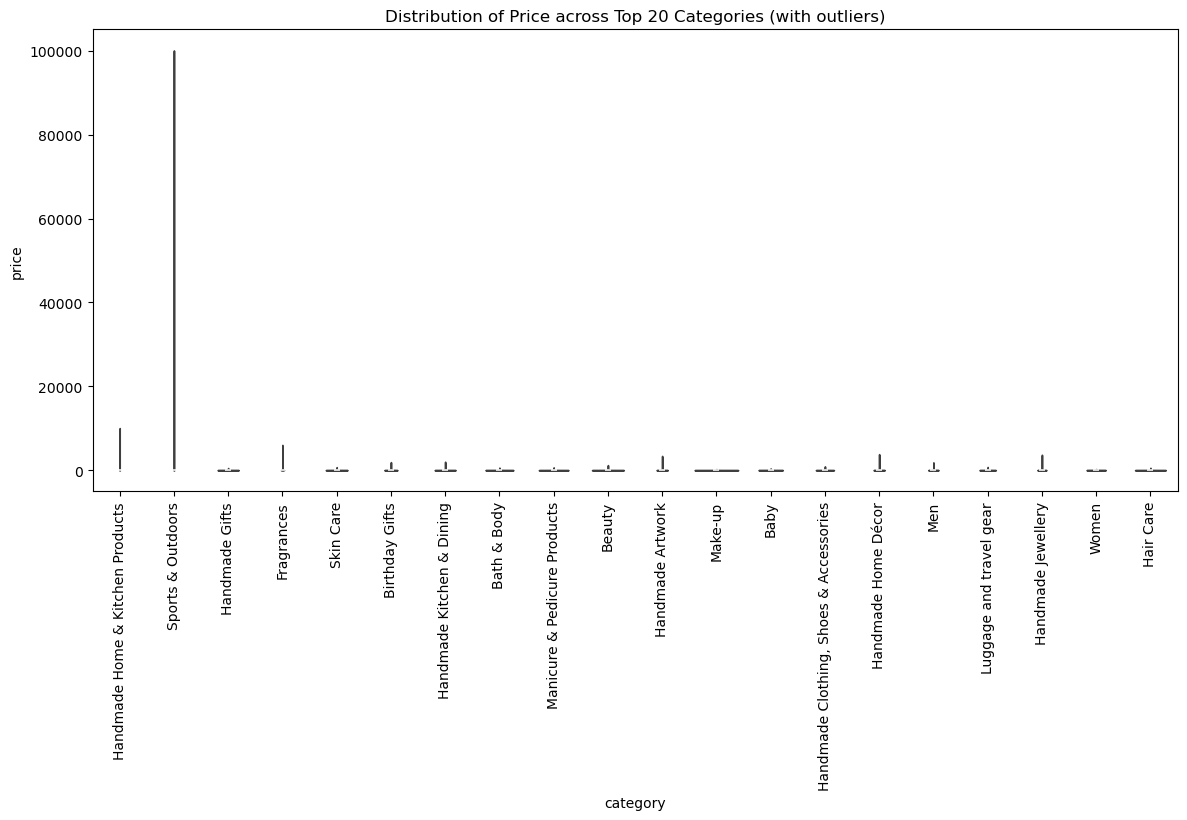

Category with highest median price (with outliers):
category
Laptops    1042.725
Name: price, dtype: float64


In [50]:
#BONUS: Do the same analysis without taking out the outliers.
# 1. Violin Plots
# ---------------------------

# Top 20 categories by count
top20_categories = df['category'].value_counts().head(20).index

plt.figure(figsize=(14, 6))
sns.violinplot(x="category", y="price", data=df[df['category'].isin(top20_categories)])
plt.xticks(rotation=90)
plt.title("Distribution of Price across Top 20 Categories (with outliers)")
plt.show()

# Median price across all categories (not filtered)
median_prices = df.groupby('category')['price'].median().sort_values(ascending=False)
print("Category with highest median price (with outliers):")
print(median_prices.head(1))

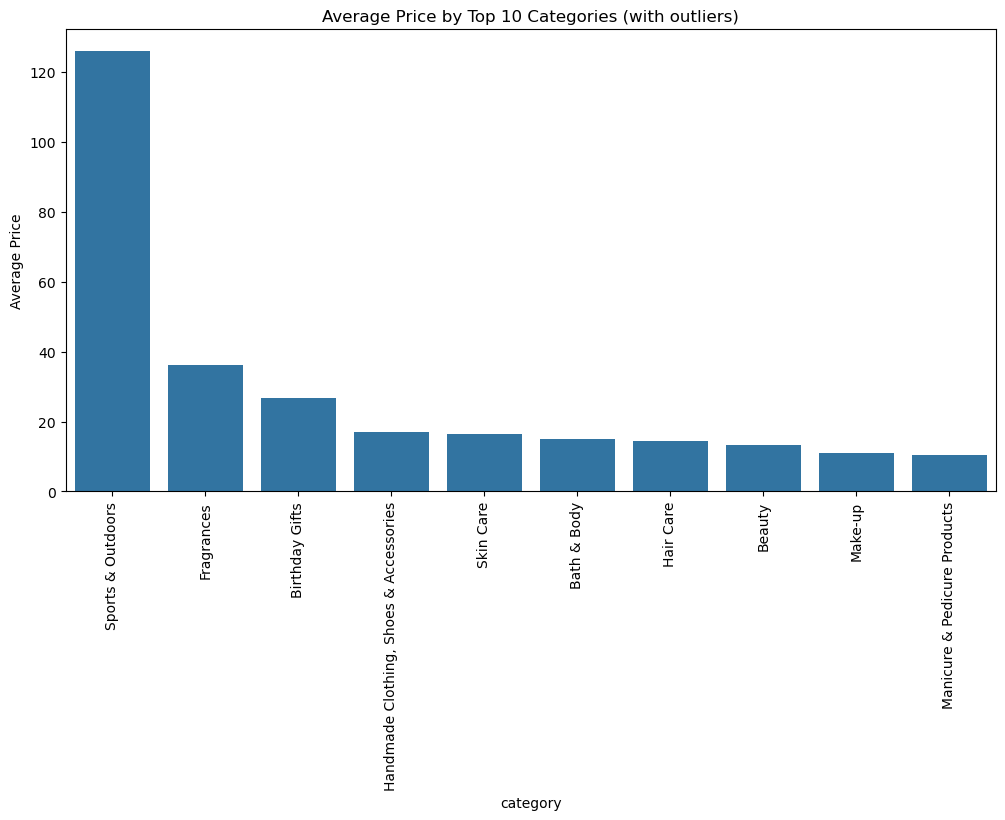

Category with highest average price (with outliers):
category
Laptops    1087.987827
Name: price, dtype: float64


In [51]:
# 2. Bar Charts (average price)
# ---------------------------

# Top 10 categories by count
top10_categories = df['category'].value_counts().head(10).index
avg_prices_top10 = df[df['category'].isin(top10_categories)].groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=avg_prices_top10.index, y=avg_prices_top10.values)
plt.xticks(rotation=90)
plt.title("Average Price by Top 10 Categories (with outliers)")
plt.ylabel("Average Price")
plt.show()

# Highest average price across all categories (not filtered)
avg_prices = df.groupby('category')['price'].mean().sort_values(ascending=False)
print("Category with highest average price (with outliers):")
print(avg_prices.head(1))

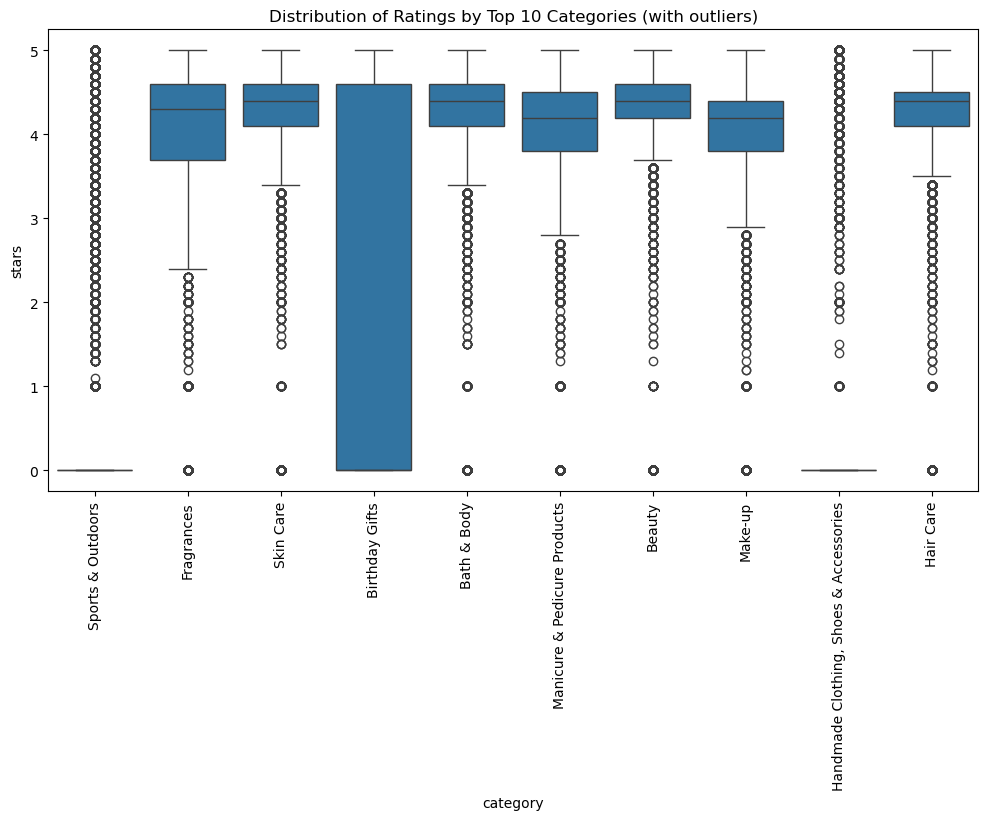

Category with highest median rating (with outliers):
category
Computer Memory    4.7
Name: stars, dtype: float64


In [52]:
# 3. Box Plots (ratings by category)
# ---------------------------

# Top 10 categories by count
plt.figure(figsize=(12, 6))
sns.boxplot(x="category", y="stars", data=df[df['category'].isin(top10_categories)])
plt.xticks(rotation=90)
plt.title("Distribution of Ratings by Top 10 Categories (with outliers)")
plt.show()

# Highest median rating across all categories (not filtered)
median_ratings = df.groupby('category')['stars'].median().sort_values(ascending=False)
print("Category with highest median rating (with outliers):")
print(median_ratings.head(1))

Correlation between price and stars (with outliers): -0.1249067326214854


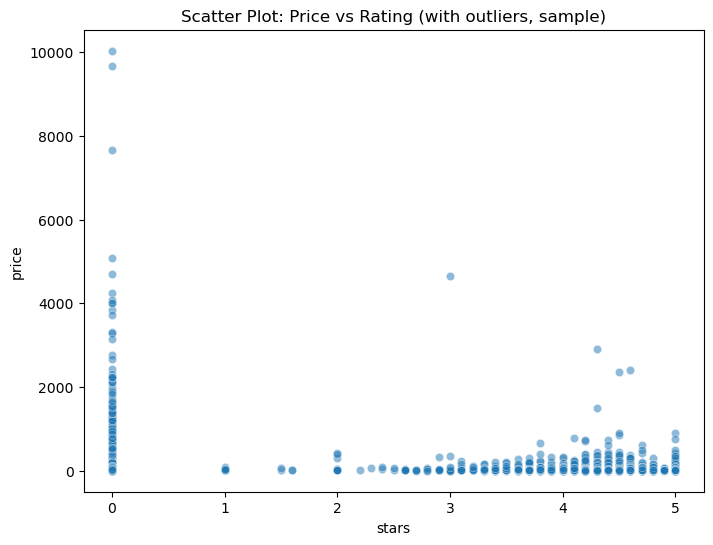

In [55]:
# 1. Correlation Coefficients
# ---------------------------
corr = df['price'].corr(df['stars'])
print("Correlation between price and stars (with outliers):", corr)


# ---------------------------
# 2a. Scatter Plot
# ---------------------------

# To avoid overcrowding, take a sample of 10,000 rows (adjust if dataset is small)
sample_df = df.sample(n=5000, random_state=42) if len(df) > 5000 else df

plt.figure(figsize=(8, 6))
sns.scatterplot(x="stars", y="price", data=sample_df, alpha=0.5)
plt.title("Scatter Plot: Price vs Rating (with outliers, sample)")
plt.show()

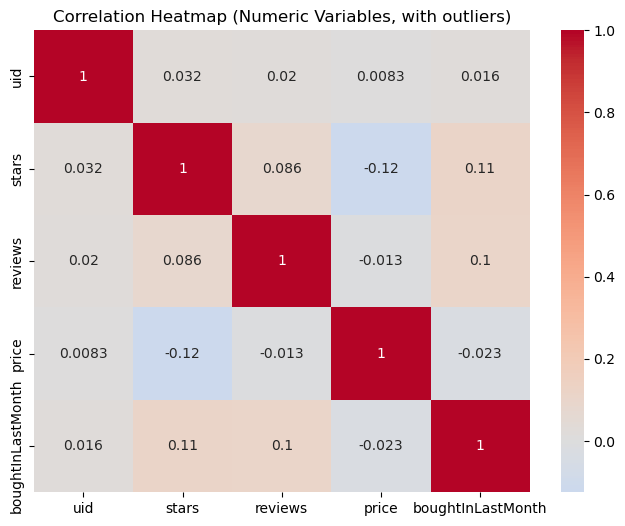

In [56]:
# 2b. Correlation Heatmap
# ---------------------------

numeric_df = df.select_dtypes(include=[np.number])  # only numeric columns
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numeric Variables, with outliers)")
plt.show()

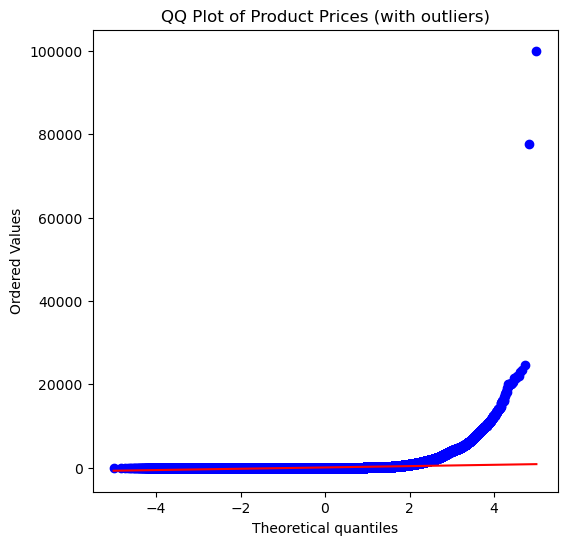

In [57]:
# 2c. QQ Plot (normality of prices)
# ---------------------------

plt.figure(figsize=(6,6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices (with outliers)")
plt.show()

***Conclusions***
1. Heavy right skew:

The points deviate strongly upward from the theoretical line at the upper quantiles. This indicates that product prices are not normally distributed and instead show a heavy right-skew due to very expensive products.

2. Extreme outliers:

The points at the top (close to 80,000–100,000) represent a very small set of extremely expensive items. These values drag the distribution far away from normality.

3. Bulk of the data:

The majority of points (near the baseline) cluster close to zero, meaning most products are relatively inexpensive compared to the extreme values.

4. Impact on analysis:

- With outliers: averages and correlations are heavily distorted (mean price is artificially inflated, variance is very high).
- Without outliers: distributions look more stable and better represent the “typical” product price.
